# Descriptive and Graphical Analysis: Nepal, 2010–2024

## Research questions

1. How did GDP per capita and GDP growth change during 2010–2024?
2. How did access to water, electricity and the Internet evolve?
3. Which selected indicators show the greatest and lowest variation,
   and how does the comparison depend on the measure used?
4. How is GDP per capita associated with life expectancy, electricity
   access and the alternative CO₂ indicator?
5. What missing observations and unusual changes affect interpretation?

## Scope

Each row represents one year for Nepal. These are 15 consecutive
country-year observations, not a random sample of countries or people.

The analysis describes the observed period. Generalisation beyond
these observations requires additional assumptions.

In [2]:
from pathlib import Path
import pandas as pd

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_FILE = ROOT / "data" / "processed" / "nepal_wdi_2010_2024_working.csv"
DICTIONARY_FILE = ROOT / "data" / "metadata" / "variable_dictionary.csv"

df = pd.read_csv(DATA_FILE)
dictionary = pd.read_csv(DICTIONARY_FILE)

indicator_columns = dictionary["Indicator"].tolist()

print("Dataset loaded:", DATA_FILE.resolve())
print("Rows:", len(df))
print("Indicators:", len(indicator_columns))

display(df.head())

Dataset loaded: /Users/zsres/Documents/M.Tech/Statistical-Inference-Assignment/data/processed/nepal_wdi_2010_2024_working.csv
Rows: 15
Indicators: 9


,Year,Country,Country_Code,GDP_per_capita,GDP_growth,Life_expectancy,Basic_drinking_water,Secondary_school_enrollment,Electricity_access,Internet_users,Forest_area,CO2_per_capita_excl_LULUCF
0,2010,Nepal,NPL,721.265221,4.816415,66.772,85.761759,55.589291,68.6,7.9300,42.434112,0.175006
1,2011,Nepal,NPL,742.617253,3.421809,67.123,86.359902,58.993511,67.3,9.0000,42.458528,0.195187
2,2012,Nepal,NPL,775.310578,4.670142,67.364,86.953284,63.141479,75.2,11.1493,42.483014,0.226080
3,2013,Nepal,NPL,801.039061,3.525153,67.598,87.541580,65.493530,77.4,13.3000,42.507429,0.228210
4,2014,Nepal,NPL,846.665542,6.011483,67.812,88.124806,67.531830,84.9,15.4400,42.531915,0.265695


In [3]:
values = df[indicator_columns]

q1 = values.quantile(0.25, interpolation="linear")
q3 = values.quantile(0.75, interpolation="linear")

descriptive = pd.DataFrame({
    "N": values.count(),
    "Mean": values.mean(),
    "Median": values.median(),
    "Min": values.min(),
    "Max": values.max(),
    "Range": values.max() - values.min(),
    "Variance": values.var(ddof=1),
    "SD": values.std(ddof=1),
    "Q1": q1,
    "Q3": q3,
    "IQR": q3 - q1,
})

descriptive.index.name = "Indicator"
descriptive = descriptive.reset_index()

unit_lookup = dictionary.set_index("Indicator")["Unit"]
descriptive.insert(
    1, "Unit", descriptive["Indicator"].map(unit_lookup)
)

TABLE_FILE = ROOT / "results" / "tables" / "descriptive_statistics.csv"
TABLE_FILE.parent.mkdir(parents=True, exist_ok=True)

# Save full precision; round only the displayed table.
descriptive.to_csv(TABLE_FILE, index=False)

display(descriptive.round(4))
print("Saved:", TABLE_FILE.resolve())

,Indicator,Unit,N,Mean,Median,Min,Max,Range,Variance,SD,Q1,Q3,IQR
0,GDP_per_capita,constant 2015 US$ per person,15,947.5189,951.8573,721.2652,1179.9550,458.6898,23203.3875,152.3266,823.8523,1069.9534,246.1011
1,GDP_growth,annual %,15,4.2581,4.6701,-2.3696,8.9773,11.3469,7.8936,2.8096,3.4735,5.8214,2.3479
2,Life_expectancy,years,15,68.5420,68.4440,66.7720,70.6360,3.8640,1.4704,1.2126,67.4860,69.2025,1.7165
3,Basic_drinking_water,% of population,15,89.7884,89.8421,85.7618,93.6401,7.8784,6.3453,2.5190,87.8332,91.7791,3.9459
4,Secondary_school_enrollment,% gross,14,74.2458,73.0929,55.5893,90.3878,34.7986,132.1898,11.4974,66.0031,84.0575,18.0544
5,Electricity_access,% of population,15,85.3000,89.9000,67.3000,97.9000,30.6000,86.9357,9.3239,79.7000,91.0000,11.3000
6,Internet_users,% of population,15,26.4581,24.3000,7.9300,46.3219,38.3919,199.7638,14.1338,14.3700,38.9772,24.6072
7,CO2_per_capita_excl_LULUCF,t CO2e/capita,15,0.3957,0.4712,0.1750,0.5898,0.4147,0.0232,0.1524,0.2457,0.5256,0.2799
8,Forest_area,% of land area,15,42.8789,42.7877,42.4341,43.5973,1.1632,0.1632,0.4040,42.5197,43.1925,0.6728


Saved: /Users/zsres/Documents/M.Tech/Statistical-Inference-Assignment/results/tables/descriptive_statistics.csv


In [4]:
from pathlib import Path
import pandas as pd

ROOT = Path.cwd()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_FILE = (
    ROOT / "data" / "processed"
    / "nepal_wdi_2010_2024_working.csv"
)

nepal = pd.read_csv(DATA_FILE).sort_values("Year").reset_index(drop=True)

TABLE_DIR = ROOT / "results" / "tables"
TABLE_DIR.mkdir(parents=True, exist_ok=True)

print("Loaded from:", DATA_FILE.resolve())
print("Rows, columns:", nepal.shape)

display(nepal.head())

Loaded from: /Users/zsres/Documents/M.Tech/Statistical-Inference-Assignment/data/processed/nepal_wdi_2010_2024_working.csv
Rows, columns: (15, 12)


,Year,Country,Country_Code,GDP_per_capita,GDP_growth,Life_expectancy,Basic_drinking_water,Secondary_school_enrollment,Electricity_access,Internet_users,Forest_area,CO2_per_capita_excl_LULUCF
0,2010,Nepal,NPL,721.265221,4.816415,66.772,85.761759,55.589291,68.6,7.9300,42.434112,0.175006
1,2011,Nepal,NPL,742.617253,3.421809,67.123,86.359902,58.993511,67.3,9.0000,42.458528,0.195187
2,2012,Nepal,NPL,775.310578,4.670142,67.364,86.953284,63.141479,75.2,11.1493,42.483014,0.226080
3,2013,Nepal,NPL,801.039061,3.525153,67.598,87.541580,65.493530,77.4,13.3000,42.507429,0.228210
4,2014,Nepal,NPL,846.665542,6.011483,67.812,88.124806,67.531830,84.9,15.4400,42.531915,0.265695


In [5]:
import numpy as np

# Validate the saved dataset used for analysis.
if nepal["Year"].tolist() != list(range(2010, 2025)):
    raise ValueError("Expected one row per year from 2010 to 2024.")

if not nepal["Country_Code"].eq("NPL").all():
    raise ValueError("Unexpected country in the analysis dataset.")

for column in indicator_columns:
    if not pd.api.types.is_numeric_dtype(nepal[column]):
        raise TypeError(f"{column}: expected numeric data.")

    observed = nepal[column].dropna()

    if observed.empty:
        raise ValueError(f"{column}: no observed values.")

    if not np.isfinite(observed.to_numpy()).all():
        raise ValueError(f"{column}: contains infinite values.")

coverage = pd.DataFrame({
    "N": nepal[indicator_columns].count(),
    "Missing": nepal[indicator_columns].isna().sum(),
})
coverage.index.name = "Indicator"

display(coverage)
coverage.to_csv(TABLE_DIR / "analysis_coverage.csv")

,N,Missing
Indicator,,
GDP_per_capita,15,0
GDP_growth,15,0
Life_expectancy,15,0
Basic_drinking_water,15,0
Secondary_school_enrollment,14,1
Electricity_access,15,0
Internet_users,15,0
CO2_per_capita_excl_LULUCF,15,0
Forest_area,15,0


In [6]:
indicator_columns = [
    "GDP_per_capita",
    "GDP_growth",
    "Life_expectancy",
    "Basic_drinking_water",
    "Secondary_school_enrollment",
    "Electricity_access",
    "Internet_users",
    "CO2_per_capita_excl_LULUCF",
    "Forest_area",
]

units = {
    "GDP_per_capita": "constant 2015 US$ per person",
    "GDP_growth": "annual %",
    "Life_expectancy": "years",
    "Basic_drinking_water": "% of population",
    "Secondary_school_enrollment": "% gross",
    "Electricity_access": "% of population",
    "Internet_users": "% of population",
    "CO2_per_capita_excl_LULUCF": "t CO2e/capita; excluding LULUCF",
    "Forest_area": "% of land area",
}

data = nepal[indicator_columns]

display(data.count().rename("Available_N").to_frame())

,Available_N
GDP_per_capita,15
GDP_growth,15
Life_expectancy,15
Basic_drinking_water,15
Secondary_school_enrollment,14
Electricity_access,15
Internet_users,15
CO2_per_capita_excl_LULUCF,15
Forest_area,15


In [7]:
# Convention: sample variance and SD, denominator N - 1.
# This convention alone does not make annual data a random sample.
DDOF = 1

descriptive = pd.DataFrame({
    "N": data.count(),
    "Mean": data.mean(),
    "Median": data.median(),
    "Minimum": data.min(),
    "Maximum": data.max(),
    "Range": data.max() - data.min(),
    "Variance": data.var(ddof=DDOF),
    "SD": data.std(ddof=DDOF),
    "Q1": data.quantile(0.25, interpolation="linear"),
    "Q3": data.quantile(0.75, interpolation="linear"),
})

descriptive["IQR"] = descriptive["Q3"] - descriptive["Q1"]

descriptive.index.name = "Indicator"
descriptive.insert(
    0,
    "Unit",
    [units[column] for column in descriptive.index],
)

# Save full precision; round only the displayed table.
output_file = TABLE_DIR / "descriptive_statistics.csv"
descriptive.to_csv(output_file)

display(
    descriptive.style.format(
        {
            column: ("{:.0f}" if column == "N" else "{:.3f}")
            for column in descriptive.columns
            if column != "Unit"
        },
        na_rep="Missing",
    )
)

print("Saved:", output_file.resolve())

,Unit,N,Mean,Median,Minimum,Maximum,Range,Variance,SD,Q1,Q3,IQR
Indicator,,,,,,,,,,,,
GDP_per_capita,constant 2015 US$ per person,15,947.519,951.857,721.265,1179.955,458.690,23203.388,152.327,823.852,1069.953,246.101
GDP_growth,annual %,15,4.258,4.670,-2.370,8.977,11.347,7.894,2.810,3.473,5.821,2.348
Life_expectancy,years,15,68.542,68.444,66.772,70.636,3.864,1.470,1.213,67.486,69.203,1.717
Basic_drinking_water,% of population,15,89.788,89.842,85.762,93.640,7.878,6.345,2.519,87.833,91.779,3.946
Secondary_school_enrollment,% gross,14,74.246,73.093,55.589,90.388,34.799,132.190,11.497,66.003,84.057,18.054
Electricity_access,% of population,15,85.300,89.900,67.300,97.900,30.600,86.936,9.324,79.700,91.000,11.300
Internet_users,% of population,15,26.458,24.300,7.930,46.322,38.392,199.764,14.134,14.370,38.977,24.607
CO2_per_capita_excl_LULUCF,t CO2e/capita; excluding LULUCF,15,0.396,0.471,0.175,0.590,0.415,0.023,0.152,0.246,0.526,0.280
Forest_area,% of land area,15,42.879,42.788,42.434,43.597,1.163,0.163,0.404,42.520,43.192,0.673


Saved: /Users/zsres/Documents/M.Tech/Statistical-Inference-Assignment/results/tables/descriptive_statistics.csv


In [8]:
selected = [
    "GDP_per_capita",
    "GDP_growth",
    "Internet_users",
]

display(descriptive.loc[selected].round(3))

extreme_rows = []

for column in selected:
    observed = nepal[["Year", column]].dropna(subset=[column])

    minimum = observed[column].min()
    maximum = observed[column].max()

    extreme_rows.append({
        "Indicator": column,
        "Minimum": minimum,
        "Minimum_years": ", ".join(
            observed.loc[
                observed[column].eq(minimum), "Year"
            ].astype(str)
        ),
        "Maximum": maximum,
        "Maximum_years": ", ".join(
            observed.loc[
                observed[column].eq(maximum), "Year"
            ].astype(str)
        ),
    })

extremes = pd.DataFrame(extreme_rows)

display(extremes.round(3))

extremes.to_csv(
    TABLE_DIR / "selected_indicator_extremes.csv",
    index=False,
)

,Unit,N,Mean,Median,Minimum,Maximum,Range,Variance,SD,Q1,Q3,IQR
Indicator,,,,,,,,,,,,
GDP_per_capita,constant 2015 US$ per person,15,947.519,951.857,721.265,1179.955,458.690,23203.388,152.327,823.852,1069.953,246.101
GDP_growth,annual %,15,4.258,4.670,-2.370,8.977,11.347,7.894,2.810,3.473,5.821,2.348
Internet_users,% of population,15,26.458,24.300,7.930,46.322,38.392,199.764,14.134,14.370,38.977,24.607


,Indicator,Minimum,Minimum_years,Maximum,Maximum_years
0,GDP_per_capita,721.265,2010,1179.955,2024
1,GDP_growth,-2.370,2020,8.977,2017
2,Internet_users,7.930,2010,46.322,2024


## Measurement and data coverage

The nine indicators are quantitative and treated as continuous
measurements in this analysis, although their recorded precision varies.
Year is a discrete time index; Country and Country_Code are identifiers.

| Indicator | Meaning and unit |
|---|---|
| GDP per capita | Output per person in constant 2015 US dollars; this is not individual income or its distribution. |
| GDP growth | Annual percentage change in real GDP; negative values indicate contraction. |
| Life expectancy | Expected years of life at birth under the mortality conditions represented by the indicator. |
| Basic drinking water | Percentage of the population using at least basic drinking-water services. |
| Secondary enrollment | Gross secondary enrollment as a percentage of the official secondary-school-age population; it can exceed 100%. |
| Electricity access | Percentage of the population with access to electricity; access does not establish reliability or service quality. |
| Internet use | Percentage of individuals using the Internet; this does not measure connection speed. |
| Alternative CO₂ indicator | CO₂ emissions excluding LULUCF per capita, recorded in t CO₂e per capita. |
| Forest area | Forest area as a percentage of land area; this does not measure forest quality or biodiversity. |

Exact definitions and source metadata are retained in the variable dictionary.

There are 15 potential observations per indicator. Secondary enrollment
is missing in 2018 and forest area in 2024; each therefore has N = 14.
The remaining seven indicators have N = 15.

Missing values remain missing. Individual summaries use available
observations, and correlations use paired non-missing observations.
No missing values are replaced with zero or interpolated.

The assigned CO₂ code is EN.ATM.CO2E.PC. The working dataset instead
uses EN.GHG.CO2.PC.CE.AR5. This substitution is explicitly labelled
and remains subject to instructor acceptance.

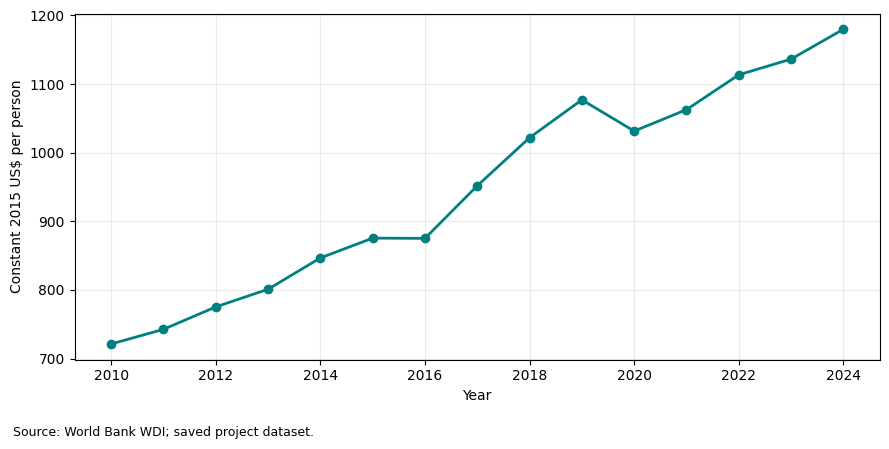

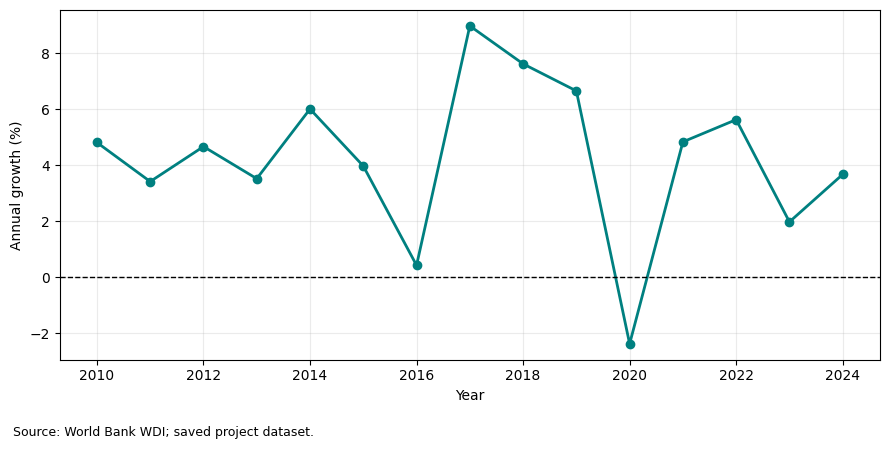

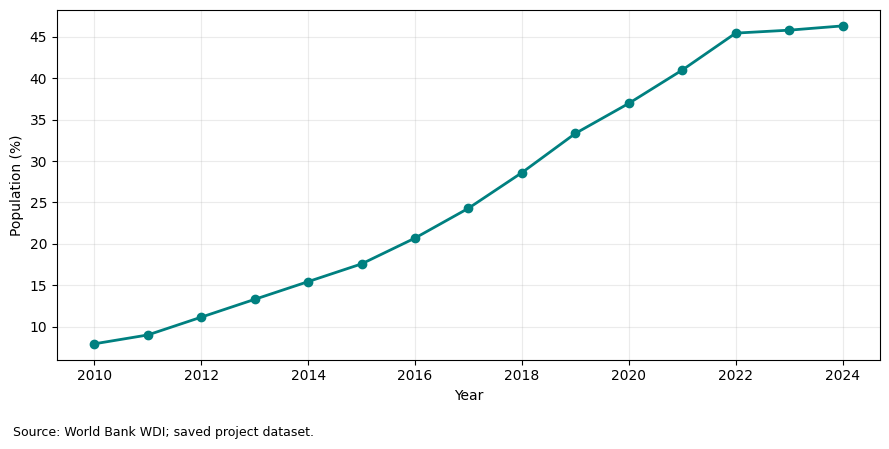

In [10]:
import matplotlib.pyplot as plt

FIGURE_DIR = ROOT / "results" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

plot_specs = [
    ("GDP_per_capita", "GDP per capita",
     "Constant 2015 US$ per person"),

    ("GDP_growth", "Annual GDP growth",
     "Annual growth (%)"),

    ("Internet_users", "Individuals using the Internet",
     "Population (%)"),
]

for figure_number, (column, title, ylabel) in enumerate(
    plot_specs, start=1
):
    # Reindexing preserves gaps if a year or value is missing.
    series = (
        nepal.set_index("Year")[column]
        .reindex(range(2010, 2025))
    )

    fig, ax = plt.subplots(figsize=(9, 4.5))

    ax.plot(
        series.index,
        series.values,
        marker="o",
        linewidth=2,
        color="teal",
    )

    
    ax.set_xlabel("Year")
    ax.set_ylabel(ylabel)
    ax.set_xticks(range(2010, 2025, 2))
    ax.grid(alpha=0.25)

    if column == "GDP_growth":
        ax.axhline(0, color="black", linewidth=1, linestyle="--")

    fig.text(
        0.02, 0.02,
        "Source: World Bank WDI; saved project dataset.",
        fontsize=9,
    )

    fig.tight_layout(rect=[0, 0.06, 1, 1])

    fig.savefig(
        FIGURE_DIR / f"figure_{figure_number:02d}_{column}.png",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

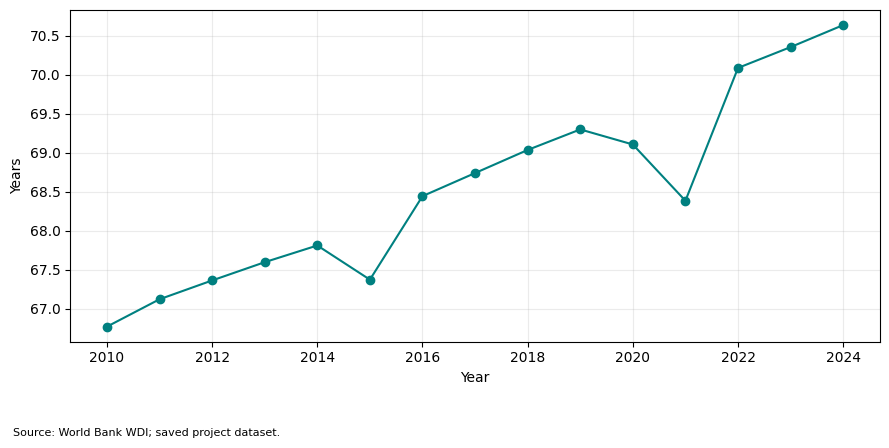

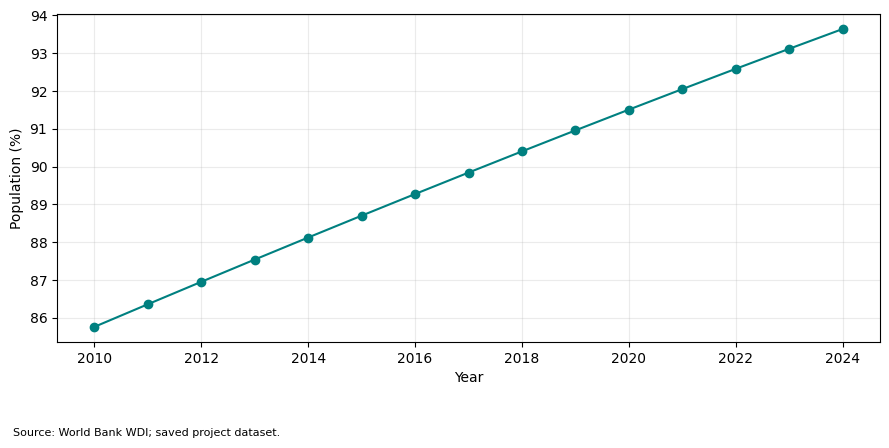

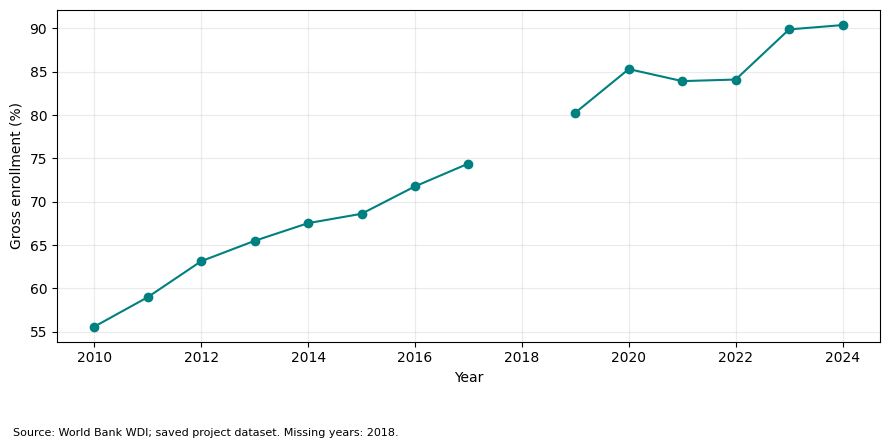

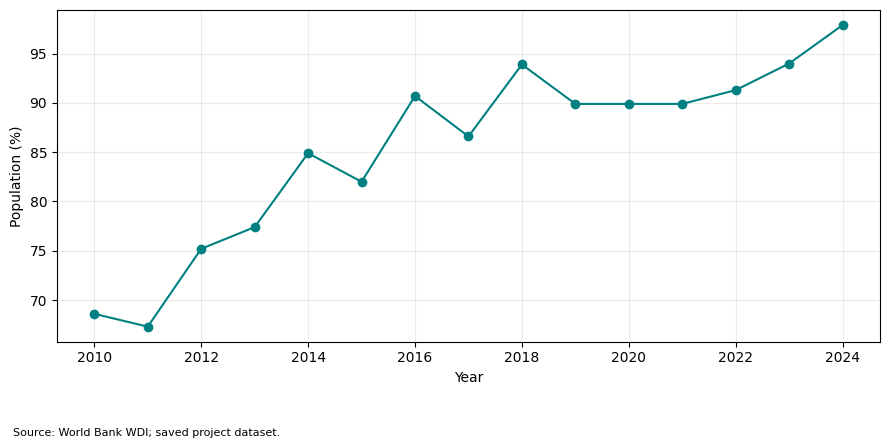

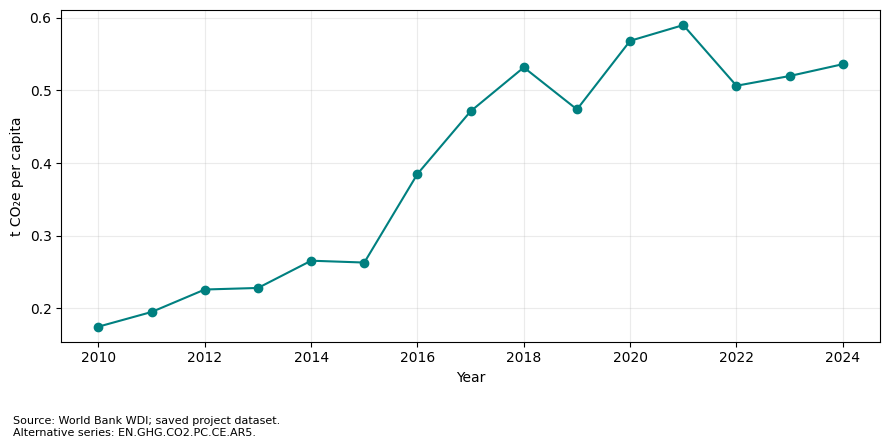

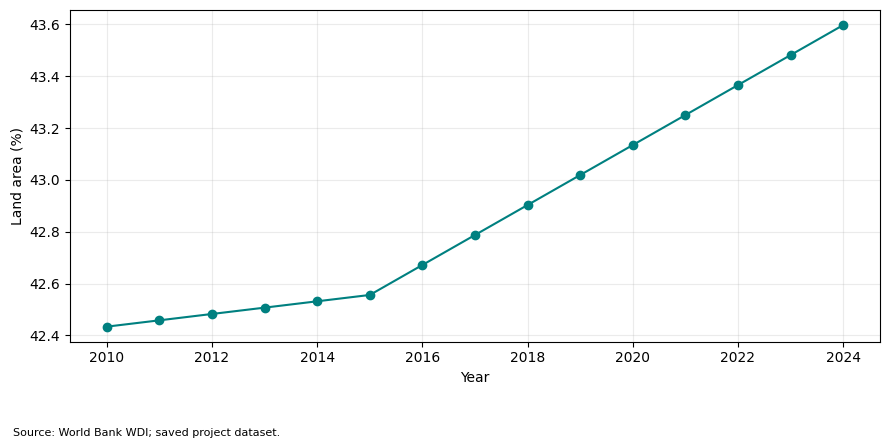

In [11]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

FIGURE_DIR = ROOT / "results" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

remaining_specs = [
    ("Life_expectancy", "Life expectancy at birth", "Years"),
    ("Basic_drinking_water", "At least basic drinking-water services",
     "Population (%)"),
    ("Secondary_school_enrollment", "Secondary school enrollment",
     "Gross enrollment (%)"),
    ("Electricity_access", "Access to electricity", "Population (%)"),
    ("CO2_per_capita_excl_LULUCF", "CO₂ emissions per capita, excluding LULUCF",
     "t CO₂e per capita"),
    ("Forest_area", "Forest area", "Land area (%)"),
]

for number, (column, title, ylabel) in enumerate(remaining_specs, start=4):
    series = (
        nepal.set_index("Year")[column]
        .reindex(range(2010, 2025))
    )

    fig, ax = plt.subplots(figsize=(9, 4.5))

    ax.plot(series.index, series.values, marker="o", color="teal")
    ax.set(
       
        xlabel="Year",
        ylabel=ylabel,
    )
    ax.set_xticks(range(2010, 2025, 2))
    ax.ticklabel_format(axis="y", style="plain", useOffset=False)
    ax.grid(alpha=0.25)

    missing_years = series.index[series.isna()].tolist()
    note = "Source: World Bank WDI; saved project dataset."

    if missing_years:
        note += " Missing years: " + ", ".join(map(str, missing_years)) + "."

    if column == "CO2_per_capita_excl_LULUCF":
        note += "\nAlternative series: EN.GHG.CO2.PC.CE.AR5."

    fig.text(0.02, 0.02, note, fontsize=8)
    fig.tight_layout(rect=[0, 0.10, 1, 1])

    fig.savefig(
        FIGURE_DIR / f"figure_{number:02d}_{column}.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

## Interpretation of the time-series figures

- Figure 1 — GDP per capita: The overall direction is upward, with
  temporary declines, including in 2020. The period was not one of
  uninterrupted growth.

- Figure 2 — GDP growth: Growth fluctuates substantially. The peak
  occurs in 2017, while 2020 is the only negative observation.

- Figure 3 — Internet use: Use increases throughout the observed
  period. The increases become smaller near the end of the series.

- Figure 4 — Life expectancy: The overall direction is upward, with
  temporary declines in 2015 and in 2020–2021, followed by recovery.
  The graph alone cannot establish the causes.

- Figure 5 — Basic drinking water: Recorded coverage rises steadily.
  The smooth series does not by itself establish whether each annual
  value came from a separate direct measurement.

- Figure 6 — Secondary enrollment: Gross enrollment rises overall,
  with a decline in 2021. The missing 2018 observation appears as a
  gap and is not interpreted as zero.

- Figure 7 — Electricity access: Coverage increases overall but has
  reversals and a recorded plateau during 2019–2021. Access should
  not be equated with reliable electricity supply.

- Figure 8 — Alternative CO₂ series: Emissions per capita increase
  overall, peak in 2021 and subsequently fluctuate. Interpretation
  is specific to the substituted indicator definition.

- Figure 9 — Forest area: All 14 available values are identical in
  the saved series. This establishes no recorded variation, not
  proof that forest conditions were physically unchanged.
  The 2024 value is missing.

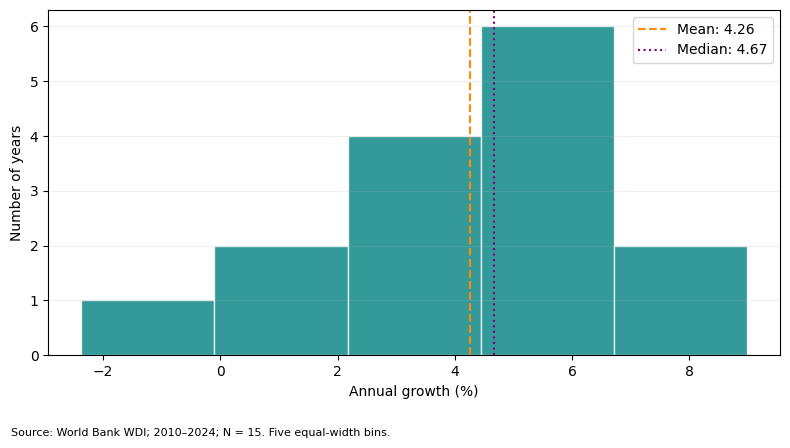

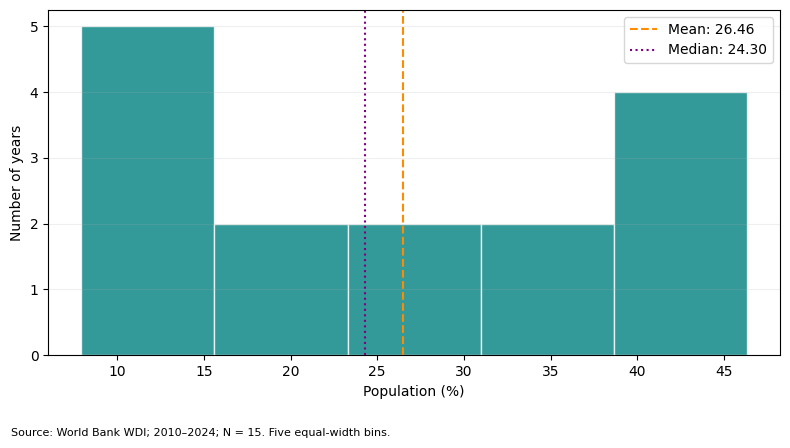

In [12]:
distribution_specs = [
    ("GDP_growth", "Annual GDP growth", "Annual growth (%)"),
    ("Internet_users", "Individuals using the Internet", "Population (%)"),
]

for number, (column, title, xlabel) in enumerate(
    distribution_specs, start=10
):
    values = nepal[column].dropna()

    fig, ax = plt.subplots(figsize=(8, 4.5))

    ax.hist(
        values,
        bins=5,
        color="teal",
        edgecolor="white",
        alpha=0.8,
    )

    ax.axvline(
        values.mean(), color="darkorange",
        linestyle="--", label=f"Mean: {values.mean():.2f}"
    )
    ax.axvline(
        values.median(), color="purple",
        linestyle=":", label=f"Median: {values.median():.2f}"
    )

    ax.set(
      
        xlabel=xlabel,
        ylabel="Number of years",
    )
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend()
    ax.grid(axis="y", alpha=0.2)

    fig.text(
        0.02, 0.02,
        f"Source: World Bank WDI; 2010–2024; N = {len(values)}. "
        "Five equal-width bins.",
        fontsize=8,
    )
    fig.tight_layout(rect=[0, 0.07, 1, 1])

    fig.savefig(
        FIGURE_DIR / f"figure_{number:02d}_histogram_{column}.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

## Histogram selection and interpretation

GDP growth was selected to examine the distribution of a fluctuating
economic indicator, including low and negative growth.

Internet use was selected to contrast this with an indicator showing
a sustained upward trajectory.

Figure 10 shows GDP growth concentrated mainly at positive values,
with a low tail containing the negative 2020 observation. The mean
lies below the median.

Figure 11 shows Internet-use values spread across low and high levels.
The mean lies above the median. This spread partly reflects change
over time rather than variation around a stable level.

Each histogram contains only 15 annual observations and uses five
equal-width bins. Apparent shape is sensitive to bin selection.
Histograms discard chronological order and cannot establish
normality or independence.

In [ ]:
heterogeneity_columns = [
    "GDP_per_capita",
    "Life_expectancy",
    "Internet_users",
    "Forest_area",
]

heterogeneity = descriptive.loc[
    heterogeneity_columns,
    ["Unit", "N", "Mean", "Variance", "SD", "Range", "IQR"],
].copy()

heterogeneity["CV_percent"] = (
    heterogeneity["SD"] / heterogeneity["Mean"] * 100
)

display(heterogeneity.round(4))

heterogeneity.to_csv(
    TABLE_DIR / "heterogeneity_comparison.csv"
)

# Rank 1 = largest numerical spread.
# Raw-measure rankings are shown only to examine scale effects.
measures = ["Variance", "SD", "Range", "IQR", "CV_percent"]

spread_ranks = heterogeneity[measures].rank(
    ascending=False,
    method="min",
)

display(spread_ranks)

spread_ranks.to_csv(
    TABLE_DIR / "heterogeneity_measure_ranks.csv"
)

,Unit,N,Mean,Variance,SD,Range,IQR,CV_percent
Indicator,,,,,,,,
GDP_per_capita,constant 2015 US$ per person,15,947.5189,23203.3875,152.3266,458.6898,246.1011,16.0764
Life_expectancy,years,15,68.5420,1.4704,1.2126,3.8640,1.7165,1.7692
Internet_users,% of population,15,26.4581,199.7638,14.1338,38.3919,24.6072,53.4195
Forest_area,% of land area,15,42.8789,0.1632,0.4040,1.1632,0.6728,0.9422


,Variance,SD,Range,IQR,CV_percent
Indicator,,,,,
GDP_per_capita,1.0,1.0,1.0,1.0,2.0
Life_expectancy,3.0,3.0,3.0,3.0,3.0
Internet_users,2.0,2.0,2.0,2.0,1.0
Forest_area,4.0,4.0,4.0,4.0,4.0


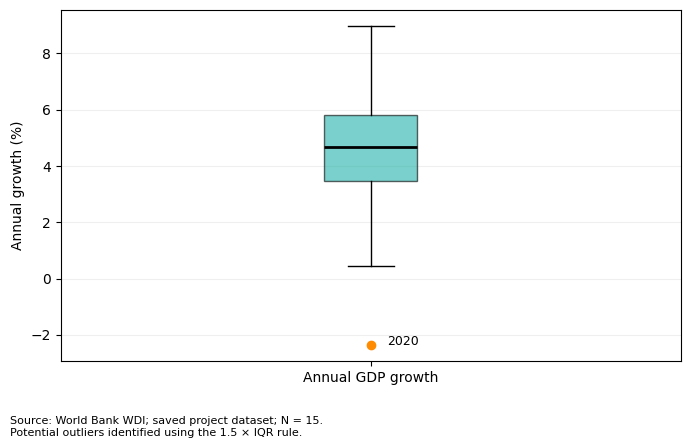

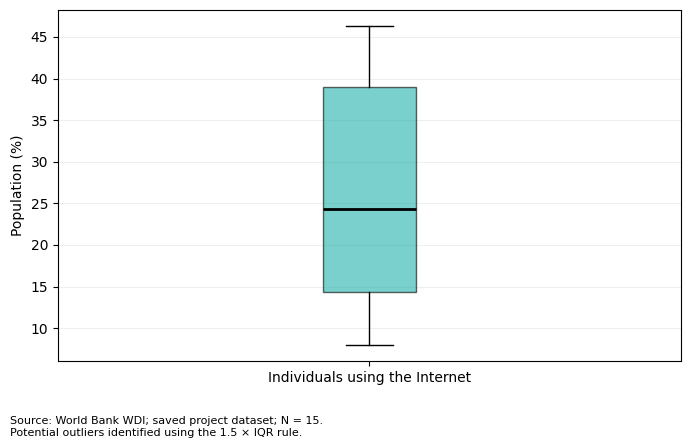

,Indicator,N,Q1,Median,Q3,IQR,Lower_fence,Upper_fence,Potential_outlier_N,Potential_outlier_years
0,GDP_growth,15,3.473,4.67,5.821,2.348,-0.048,9.343,1,2020
1,Internet_users,15,14.370,24.30,38.977,24.607,-22.541,75.888,0,None


In [13]:
import matplotlib.pyplot as plt

FIGURE_DIR = ROOT / "results" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

boxplot_specs = [
    ("GDP_growth", "Annual GDP growth", "Annual growth (%)"),
    ("Internet_users", "Individuals using the Internet", "Population (%)"),
]

outlier_rows = []

for number, (column, title, ylabel) in enumerate(
    boxplot_specs, start=12
):
    values = nepal[column].dropna()

    # Quartiles and middle 50% spread.
    q1 = values.quantile(0.25, interpolation="linear")
    q3 = values.quantile(0.75, interpolation="linear")
    iqr = q3 - q1

    # Boundaries used to flag potential outliers.
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    flagged = nepal.loc[
        nepal[column].lt(lower_fence)
        | nepal[column].gt(upper_fence),
        ["Year", column],
    ]

    outlier_rows.append({
        "Indicator": column,
        "N": len(values),
        "Q1": q1,
        "Median": values.median(),
        "Q3": q3,
        "IQR": iqr,
        "Lower_fence": lower_fence,
        "Upper_fence": upper_fence,
        "Potential_outlier_N": len(flagged),
        "Potential_outlier_years": (
            ", ".join(flagged["Year"].astype(str)) or "None"
        ),
    })

    fig, ax = plt.subplots(figsize=(7, 4.5))

    ax.boxplot(
        values.to_numpy(),
        whis=1.5,
        patch_artist=True,
        boxprops={"facecolor": "lightseagreen", "alpha": 0.6},
        medianprops={"color": "black", "linewidth": 2},
        flierprops={
            "marker": "o",
            "markerfacecolor": "darkorange",
            "markeredgecolor": "darkorange",
        },
    )

    # Label potential outliers with their observation year.
    for _, row in flagged.iterrows():
        ax.annotate(
            str(int(row["Year"])),
            xy=(1, row[column]),
            xytext=(12, 0),
            textcoords="offset points",
            fontsize=9,
        )

    ax.set_xticks([1])
    ax.set_xticklabels([title])
    ax.set_ylabel(ylabel)

    ax.grid(axis="y", alpha=0.2)

    fig.text(
        0.02, 0.02,
        f"Source: World Bank WDI; saved project dataset; N = {len(values)}.\n"
        "Potential outliers identified using the 1.5 × IQR rule.",
        fontsize=8,
    )

    fig.tight_layout(rect=[0, 0.10, 1, 1])

    fig.savefig(
        FIGURE_DIR / f"figure_{number:02d}_boxplot_{column}.png",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

outlier_summary = pd.DataFrame(outlier_rows)

display(outlier_summary.round(3))

outlier_summary.to_csv(
    TABLE_DIR / "boxplot_outlier_summary.csv",
    index=False,
)

## Boxplot interpretation

Figure 12 — GDP growth:
The median is 4.670%. Q1 is 3.473% and Q3 is 5.821%, giving an
IQR of 2.348 percentage points. The middle 50% of observed annual
growth values lie between these quartiles.

The 2020 observation falls below the lower 1.5 × IQR fence and is
flagged as a potential outlier. It remains in the analysis.

Figure 13 — Internet use:
The median is 24.300%. Q1 is 14.370% and Q3 is 38.977%, giving an
IQR of 24.607 percentage points. No observations fall outside the
1.5 × IQR fences.

The Internet-use spread partly reflects the time trend. The absence
of flagged outliers does not establish normality or data accuracy.

Boxplot whiskers extend to the most extreme observations within the
fences; they are not necessarily located exactly at the fences.

In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_FILE = (
    ROOT / "data" / "processed"
    / "nepal_wdi_2010_2024_working.csv"
)

nepal = pd.read_csv(DATA_FILE).sort_values("Year")

TABLE_DIR = ROOT / "results" / "tables"
FIGURE_DIR = ROOT / "results" / "figures"

TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Loaded:", DATA_FILE.resolve())
display(nepal.head())

Loaded: /Users/zsres/Documents/M.Tech/Statistical-Inference-Assignment/data/processed/nepal_wdi_2010_2024_working.csv


,Year,Country,Country_Code,GDP_per_capita,GDP_growth,Life_expectancy,Basic_drinking_water,Secondary_school_enrollment,Electricity_access,Internet_users,Forest_area,CO2_per_capita_excl_LULUCF
0,2010,Nepal,NPL,721.265221,4.816415,66.772,85.761759,55.589291,68.6,7.9300,42.434112,0.175006
1,2011,Nepal,NPL,742.617253,3.421809,67.123,86.359902,58.993511,67.3,9.0000,42.458528,0.195187
2,2012,Nepal,NPL,775.310578,4.670142,67.364,86.953284,63.141479,75.2,11.1493,42.483014,0.226080
3,2013,Nepal,NPL,801.039061,3.525153,67.598,87.541580,65.493530,77.4,13.3000,42.507429,0.228210
4,2014,Nepal,NPL,846.665542,6.011483,67.812,88.124806,67.531830,84.9,15.4400,42.531915,0.265695


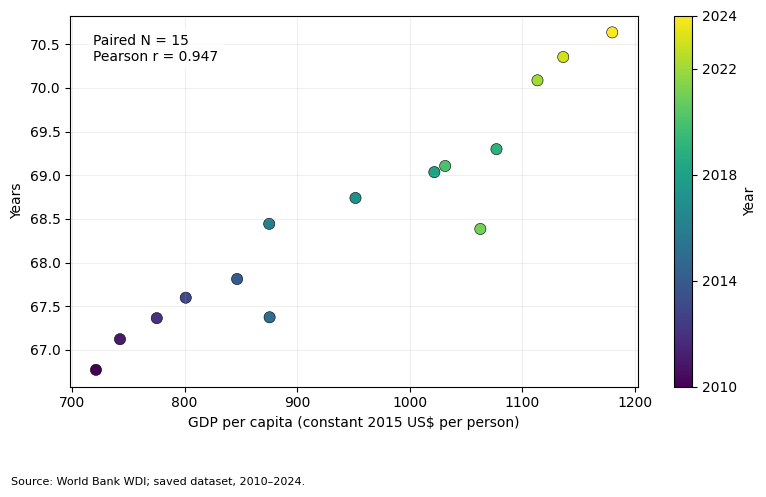

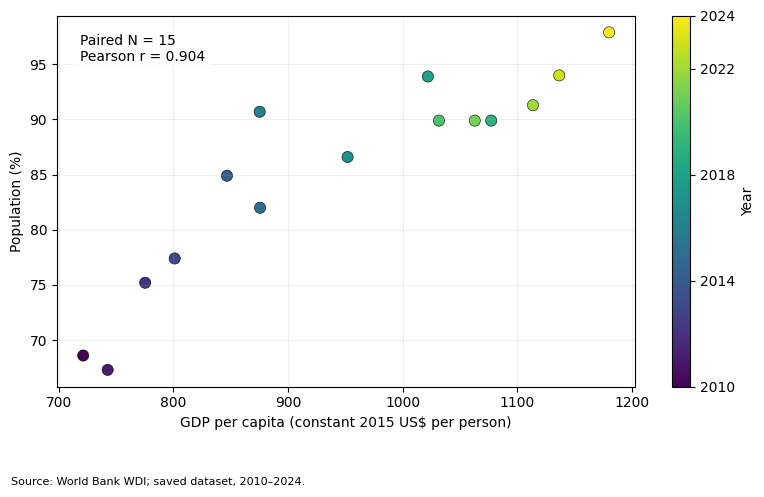

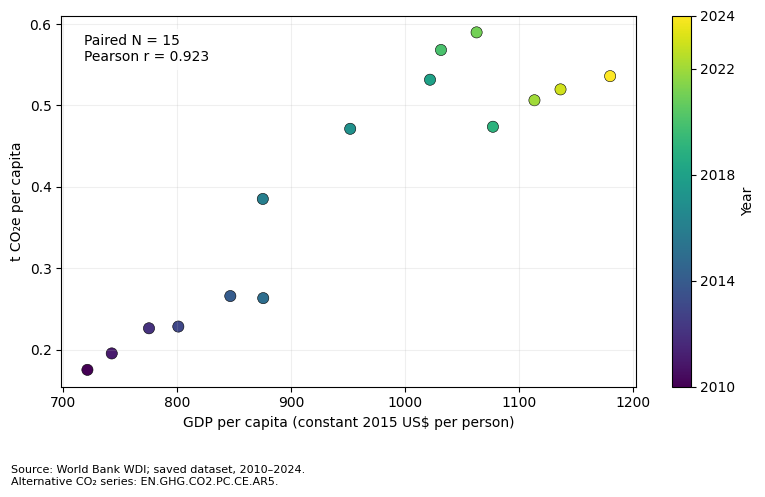

,X,Y,Paired_N,Excluded_years,Sample_covariance,Covariance_unit,Pearson_r
0,GDP_per_capita,Life_expectancy,15,None,174.8354,(constant 2015 US$ per person) × (Years),0.9465
1,GDP_per_capita,Electricity_access,15,None,1284.0841,(constant 2015 US$ per person) × (Population (%)),0.9041
2,GDP_per_capita,CO2_per_capita_excl_LULUCF,15,None,21.4271,(constant 2015 US$ per person) × (t CO₂e per c...,0.9229


In [14]:
pairs = [
    ("Life_expectancy", "Life expectancy", "Years"),
    ("Electricity_access", "Electricity access", "Population (%)"),
    (
        "CO2_per_capita_excl_LULUCF",
        "CO₂ emissions per capita, excluding LULUCF",
        "t CO₂e per capita",
    ),
]

rows = []

for number, (column, label, ylabel) in enumerate(pairs, start=14):
    # Use only years where BOTH indicators are available.
    paired = nepal[["Year", "GDP_per_capita", column]].dropna(
        subset=["GDP_per_capita", column]
    )

    x = paired["GDP_per_capita"]
    y = paired[column]

    covariance = x.cov(y, ddof=1)
    correlation = x.corr(y, method="pearson")

    rows.append({
        "X": "GDP_per_capita",
        "Y": column,
        "Paired_N": len(paired),
        "Excluded_years": ", ".join(
            nepal.loc[
                nepal["GDP_per_capita"].isna() | nepal[column].isna(),
                "Year",
            ].astype(str)
        ) or "None",
        "Sample_covariance": covariance,
        "Covariance_unit": f"(constant 2015 US$ per person) × ({ylabel})",
        "Pearson_r": correlation,
    })

    fig, ax = plt.subplots(figsize=(8, 5))

    points = ax.scatter(
        x, y,
        c=paired["Year"],
        cmap="viridis",
        vmin=2010,
        vmax=2024,
        s=65,
        edgecolors="black",
        linewidths=0.4,
    )

    colourbar = fig.colorbar(points, ax=ax)
    colourbar.set_label("Year")
    colourbar.set_ticks([2010, 2014, 2018, 2022, 2024])

    ax.set(
        
        xlabel="GDP per capita (constant 2015 US$ per person)",
        ylabel=ylabel,
    )

    ax.text(
        0.04, 0.95,
        f"Paired N = {len(paired)}\nPearson r = {correlation:.3f}",
        transform=ax.transAxes,
        va="top",
        bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none"},
    )
    ax.grid(alpha=0.2)

    note = "Source: World Bank WDI; saved dataset, 2010–2024."
    if column == "CO2_per_capita_excl_LULUCF":
        note += "\nAlternative CO₂ series: EN.GHG.CO2.PC.CE.AR5."

    fig.text(0.02, 0.02, note, fontsize=8)
    fig.tight_layout(rect=[0, 0.10, 1, 1])

    fig.savefig(
        FIGURE_DIR / f"figure_{number:02d}_scatter_GDP_vs_{column}.png",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

correlation_summary = pd.DataFrame(rows)

display(correlation_summary.round(4))

correlation_summary.to_csv(
    TABLE_DIR / "correlation_summary.csv",
    index=False,
)

## Covariance and correlation interpretation

All three pairs contain 15 paired observations; no years are excluded.

- Figure 14: GDP per capita and life expectancy have Pearson
  r ≈ 0.947, a strong positive observed linear association.

- Figure 15: GDP per capita and electricity access have Pearson
  r ≈ 0.904, also a strong positive observed linear association.

- Figure 16: GDP per capita and the alternative CO₂ indicator have
  Pearson r ≈ 0.923, a strong positive observed linear association.

The corresponding sample covariances are positive and are reported
in the calculated table. Covariance carries the product of the
variables' units, so its magnitude is not directly comparable across
these three pairs. Pearson r is dimensionless.

The year colours help reveal the chronological progression. Common
trends may contribute substantially to these correlations.

These associations do not demonstrate that GDP per capita causes
changes in the other indicators. Confounding, time trends and
reverse relationships remain possible.

Correlation significance tests have not been included. Their
inclusion depends on course coverage and appropriate assumptions
for these annual observations.

## Interpretation of three selected indicators

### GDP per capita

The observed mean is approximately US$947.519 and the median is
US$951.857, both in constant 2015 dollars per person. Their proximity
suggests limited mean–median asymmetry, but does not establish a
symmetric distribution.

The minimum is US$721.265 in 2010 and the maximum is US$1,179.955
in 2024. These show that the highest observed level occurred at the
end of the period and the lowest at the beginning.

The mean summarises the period's level, but conceals the upward
trajectory and temporary declines. It should be read alongside
the time-series graph.

### GDP growth

Mean annual growth is 4.258%, below the median of 4.670%.
This is consistent with low-growth observations pulling the mean down.

The minimum is −2.370% in 2020, indicating contraction. The maximum
is 8.977% in 2017. The arithmetic mean gives equal weight to each year;
it is not a compound annual growth rate.

The mean is useful as an overall summary but hides substantial
year-to-year variation, including the negative observation.

### Internet use

The mean is 26.458% and the median is 24.300%. The higher mean is
consistent with some asymmetry towards higher values, but the
histogram must also be considered.

The minimum is 7.930% in 2010 and the maximum is 46.322% in 2024.
The large change reflects expansion of Internet use across the period.

The period mean is not a description of current Internet use.
The time-series graph is more informative about the progression.

All values above refer to the saved dataset. Calculations retain
full precision; these interpretations use rounded results.

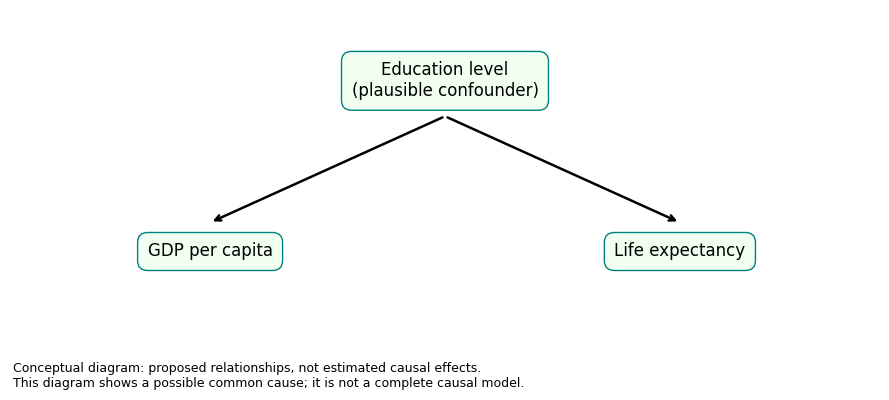

In [15]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 4))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")

positions = {
    "Education level\n(plausible confounder)": (0.50, 0.78),
    "GDP per capita": (0.23, 0.25),
    "Life expectancy": (0.77, 0.25),
}

for label, position in positions.items():
    ax.text(
        *position,
        label,
        ha="center",
        va="center",
        fontsize=12,
        bbox={
            "boxstyle": "round,pad=0.6",
            "facecolor": "honeydew",
            "edgecolor": "teal",
        },
    )

for endpoint in [(0.23, 0.34), (0.77, 0.34)]:
    ax.annotate(
        "",
        xy=endpoint,
        xytext=(0.50, 0.67),
        arrowprops={"arrowstyle": "->", "linewidth": 1.8},
    )



fig.text(
    0.02, 0.02,
    "Conceptual diagram: proposed relationships, not estimated causal effects.\n"
    "This diagram shows a possible common cause; it is not a complete causal model.",
    fontsize=9,
)

fig.tight_layout(rect=[0, 0.12, 1, 1])

fig.savefig(
    FIGURE_DIR / "figure_17_confounding_diagram.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

## Interpretation of the proposed confounder

X = GDP per capita
Y = Life expectancy
Z = Education level

Education is a plausible common influence: it may be associated with
productivity and earnings, and also with health knowledge and the use
of health services.

Consequently, part of the observed GDP–life-expectancy association
could reflect differences in education rather than a direct effect
of GDP per capita.

The diagram proposes a possible mechanism; it does not estimate or
verify causal effects. Education level is not identical to the
secondary gross-enrollment indicator, which would be only an
imperfect proxy.

No statistical adjustment for education has been performed.
The correlation describes association within the observed years
and cannot isolate a causal effect.

In [ ]:
growth = nepal["GDP_growth"].dropna()

q1 = growth.quantile(0.25, interpolation="linear")
q3 = growth.quantile(0.75, interpolation="linear")
iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

unusual_observation = nepal.loc[
    nepal["Year"].between(2018, 2022),
    ["Year", "GDP_growth"],
].copy()

unusual_observation["Lower_fence"] = lower_fence
unusual_observation["Upper_fence"] = upper_fence

unusual_observation["Potential_outlier"] = (
    unusual_observation["GDP_growth"].lt(lower_fence)
    | unusual_observation["GDP_growth"].gt(upper_fence)
)

display(unusual_observation.round(3))

unusual_observation.to_csv(
    TABLE_DIR / "unusual_observation_GDP_growth_2020.csv",
    index=False,
)

,Year,GDP_growth,Lower_fence,Upper_fence,Potential_outlier
8,2018,7.622,-0.048,9.343,False
9,2019,6.657,-0.048,9.343,False
10,2020,-2.370,-0.048,9.343,True
11,2021,4.838,-0.048,9.343,False
12,2022,5.631,-0.048,9.343,False


In [ ]:
import numpy as np
import pandas as pd

inference_columns = [
    "GDP_growth",
    "Life_expectancy",
]

inference_rows = []

for column in inference_columns:
    values = nepal[column].dropna()

    n = len(values)
    mean = values.mean()
    sample_sd = values.std(ddof=1)

    # Valid as a mean SE only under suitable independence
    # and common-distribution assumptions.
    se_iid = sample_sd / np.sqrt(n)

    inference_rows.append({
        "Indicator": column,
        "N": n,
        "Mean": mean,
        "Sample_SD": sample_sd,
        "SE_under_IID_assumption": se_iid,
        "Population_sigma_known": False,
        "Status": "Preparation only; inferential method pending",
    })

inference_preparation = pd.DataFrame(inference_rows)

display(inference_preparation.round(4))

inference_preparation.to_csv(
    TABLE_DIR / "inference_preparation.csv",
    index=False,
)

,Indicator,N,Mean,Sample_SD,SE_under_IID_assumption,Population_sigma_known,Status
0,GDP_growth,15,4.2581,2.8096,0.7254,False,Preparation only; inferential method pending
1,Life_expectancy,15,68.5420,1.2126,0.3131,False,Preparation only; inferential method pending


## Investigation of the unusual 2020 GDP-growth observation

GDP growth in the saved dataset is −2.370% in 2020, compared with
6.657% in 2019 and 4.838% in 2021. The surrounding-year calculation
is retained in the accompanying table.

The 2020 value is the minimum in the observed period and is flagged
by the 1.5 × IQR rule.

A World Bank release dated 12 April 2021 describes Nepal's economic
contraction in FY2020 and the subsequent recovery in the context
of the COVID-19 pandemic.

This supports interpreting the observation as consistent with a
genuine economic contraction rather than deleting it as an obvious
data-entry error. It does not establish the causal contribution
of individual factors.

The historical release uses fiscal-year language and an earlier
publication vintage. It provides context, not independent verification
of the exact value in the current saved WDI series.

Decision: Retain the original observation without alteration.

Source:
[World Bank, 12 April 2021 — Export competitiveness key to Nepal’s recovery](https://www.worldbank.org/en/news/press-release/2021/04/12/export-competitiveness-key-to-nepal-s-green-resilient-and-inclusive-recovery-states-new-world-bank-report)